# Fuzzy Q-Learning for CartPole-v1

**Aim:** Design and implement a Fuzzy Q-Learning agent that learns to balance a pole in the `CartPole-v1` environment by combining fuzzy state representation with Q-learning.


In [2]:
import itertools
import random
from dataclasses import dataclass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gymnasium as gym

SEED = 42
EPISODES = 1000
MAX_STEPS = 500

np.random.seed(SEED)
random.seed(SEED)

print("Gymnasium version:", gym.__version__)
print("Training episodes:", EPISODES)


Gymnasium version: 1.3.0
Training episodes: 1000


### 1. Convert continuous states into fuzzy linguistic variables. (Try for 2 and 5 fuzzy sets)

In [3]:
# CartPole has four continuous state variables.
STATE_NAMES = [
    "Cart Position",
    "Cart Velocity",
    "Pole Angle",
    "Pole Angular Velocity",
]

STATE_RANGES = np.array([
    [-2.4, 2.4],
    [-3.0, 3.0],
    [-0.2095, 0.2095],
    [-3.0, 3.0],
], dtype=float)

N_ACTIONS = 2

def clip_state(state):
    return np.clip(
        np.asarray(state, dtype=float),
        STATE_RANGES[:, 0],
        STATE_RANGES[:, 1]
    )

pd.DataFrame(
    STATE_RANGES,
    index=STATE_NAMES,
    columns=["Minimum", "Maximum"]
)

,Minimum,Maximum
Cart Position,-2.4000,2.4000
Cart Velocity,-3.0000,3.0000
Pole Angle,-0.2095,0.2095
Pole Angular Velocity,-3.0000,3.0000


In [4]:
# Triangular and trapezoidal membership functions.

def triangular(x, a, b, c):
    if x <= a or x >= c:
        return 1.0 if x == b else 0.0
    if x == b:
        return 1.0
    if x < b:
        return (x - a) / (b - a) if b != a else 1.0
    return (c - x) / (c - b) if c != b else 1.0


def trapezoidal(x, a, b, c, d):
    if x < a or x > d:
        return 0.0
    if b <= x <= c:
        return 1.0
    if x < b:
        return (x - a) / (b - a) if b != a else 1.0
    return (d - x) / (d - c) if d != c else 1.0


def evaluate_membership(x, params, kind):
    if kind == "triangular":
        return triangular(x, *params)
    if kind == "trapezoidal":
        return trapezoidal(x, *params)
    raise ValueError("Membership type must be triangular or trapezoidal.")

In [5]:
# Create overlapping linguistic fuzzy sets.
# 2 sets: Negative, Positive
# 5 sets: NL, NS, ZE, PS, PL

def make_fuzzy_sets(low, high, n_sets, kind):
    if n_sets not in (2, 5):
        raise ValueError("Use 2 or 5 fuzzy sets for this lab.")

    labels = (
        ["Negative", "Positive"]
        if n_sets == 2
        else ["NL", "NS", "ZE", "PS", "PL"]
    )

    centers = np.linspace(low, high, n_sets)
    step = centers[1] - centers[0]
    fuzzy_sets = []

    for i, center in enumerate(centers):
        if kind == "triangular":
            a = low if i == 0 else center - step
            c = high if i == n_sets - 1 else center + step
            params = (a, center, c)
        elif kind == "trapezoidal":
            if i == 0:
                params = (low, low, center, center + step)
            elif i == n_sets - 1:
                params = (center - step, center, high, high)
            else:
                params = (
                    center - step,
                    center - step / 2,
                    center + step / 2,
                    center + step
                )
        else:
            raise ValueError("kind must be triangular or trapezoidal.")

        fuzzy_sets.append({
            "label": labels[i],
            "params": params
        })

    return fuzzy_sets


def build_partitions(n_sets, kind):
    return [
        make_fuzzy_sets(low, high, n_sets, kind)
        for low, high in STATE_RANGES
    ]


for n_sets in [2, 5]:
    for kind in ["triangular", "trapezoidal"]:
        partitions = build_partitions(n_sets, kind)
        print(f"{n_sets} sets + {kind}: {[len(p) for p in partitions]}")

2 sets + triangular: [2, 2, 2, 2]
2 sets + trapezoidal: [2, 2, 2, 2]
5 sets + triangular: [5, 5, 5, 5]
5 sets + trapezoidal: [5, 5, 5, 5]


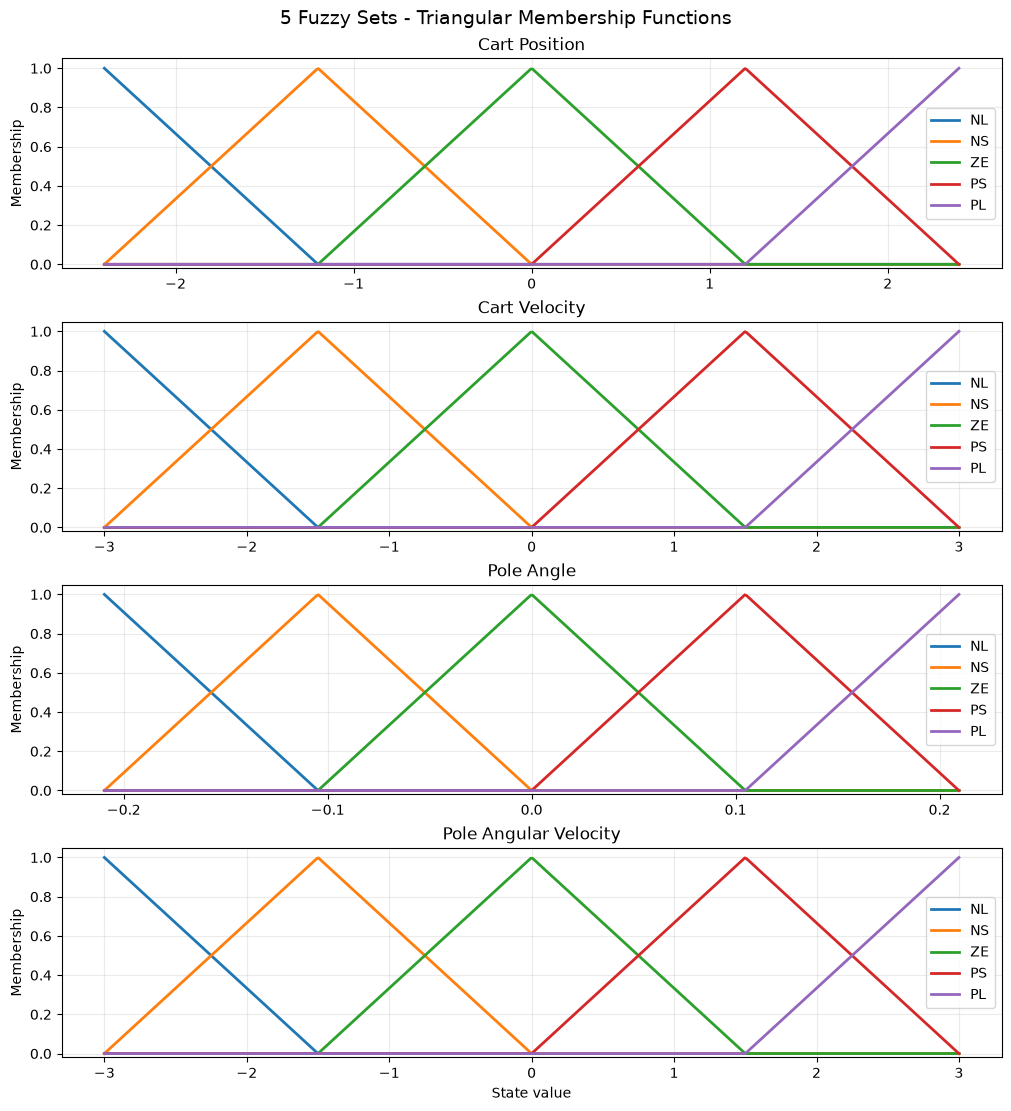

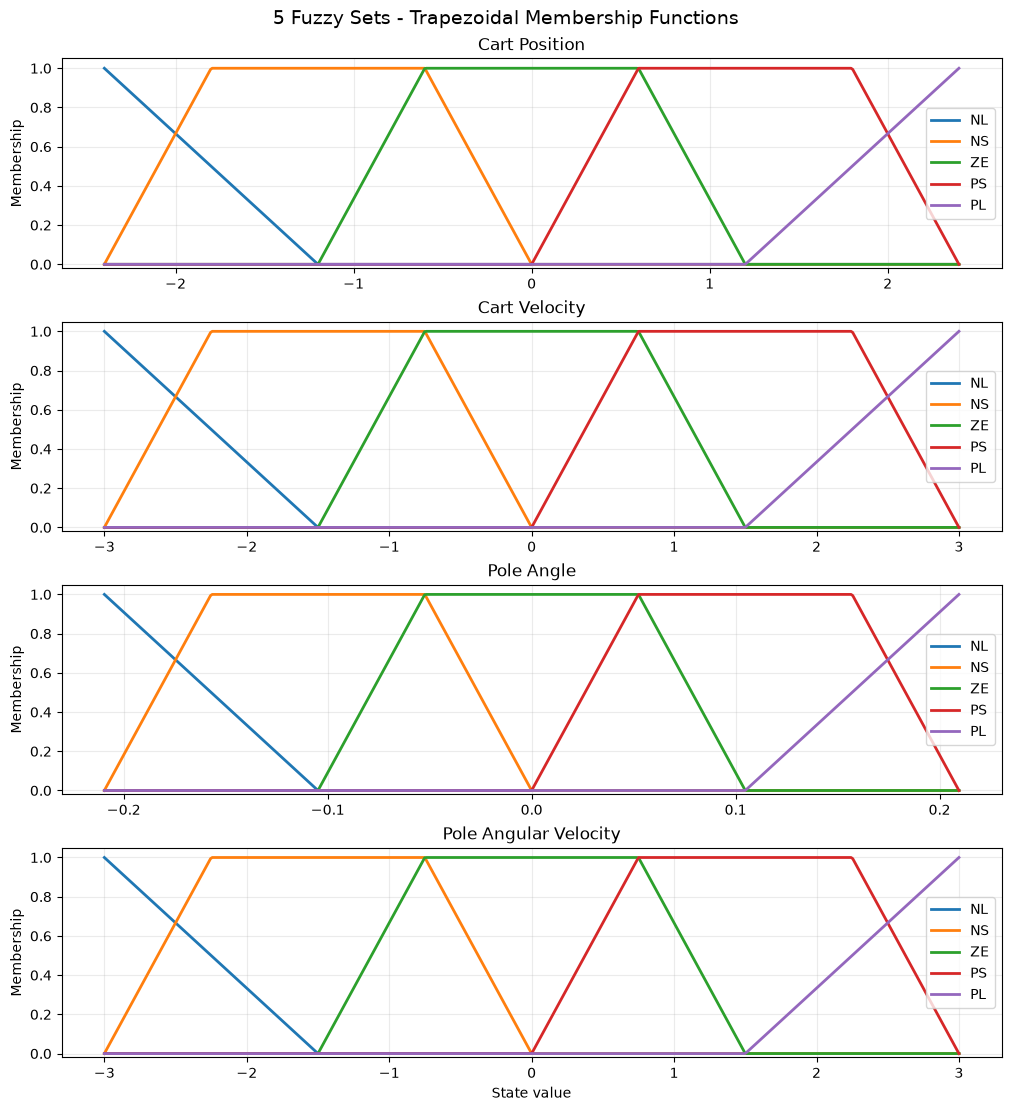

In [6]:
# The following plots show the fuzzy linguistic variables used by the agent.

def plot_membership_functions(n_sets, kind):
    partitions = build_partitions(n_sets, kind)

    fig, axes = plt.subplots(4, 1, figsize=(10, 11), constrained_layout=True)

    for variable_index, ax in enumerate(axes):
        low, high = STATE_RANGES[variable_index]
        x_values = np.linspace(low, high, 500)

        for fuzzy_set in partitions[variable_index]:
            params = fuzzy_set["params"]
            y_values = [
                evaluate_membership(x, params, kind)
                for x in x_values
            ]
            ax.plot(
                x_values,
                y_values,
                linewidth=2,
                label=fuzzy_set["label"]
            )

        ax.set_title(STATE_NAMES[variable_index])
        ax.set_ylabel("Membership")
        ax.set_ylim(-0.02, 1.05)
        ax.grid(alpha=0.25)
        ax.legend()

    axes[-1].set_xlabel("State value")
    fig.suptitle(
        f"{n_sets} Fuzzy Sets - {kind.title()} Membership Functions",
        fontsize=14
    )
    plt.show()


plot_membership_functions(5, "triangular")
plot_membership_functions(5, "trapezoidal")


### 2. Construct Fuzzy Rules/states

In [7]:
# Each fuzzy state/rule is one combination of the four linguistic variables.
# Number of possible rules:
# 2 sets -> 2^4 = 16
# 5 sets -> 5^4 = 625

def generate_rules(n_sets):
    return list(itertools.product(range(n_sets), repeat=4))


for n_sets in [2, 5]:
    rules = generate_rules(n_sets)
    print(f"{n_sets} fuzzy sets -> {len(rules)} fuzzy rules/states")

2 fuzzy sets -> 16 fuzzy rules/states
5 fuzzy sets -> 625 fuzzy rules/states


In [8]:
# Example of fuzzifying one continuous CartPole observation.

def fuzzify_state(state, partitions):
    state = clip_state(state)
    membership_values = []

    for value, partition in zip(state, partitions):
        values = []
        for fuzzy_set in partition:
            params = fuzzy_set["params"]
            kind = "triangular" if len(params) == 3 else "trapezoidal"
            values.append(evaluate_membership(value, params, kind))
        membership_values.append(np.asarray(values))

    return membership_values


example_state = np.array([0.2, -0.4, 0.03, 0.5])
example_partitions = build_partitions(5, "triangular")
example_memberships = fuzzify_state(example_state, example_partitions)

for name, memberships in zip(STATE_NAMES, example_memberships):
    print(name, ":", np.round(memberships, 3))

Cart Position : [0.    0.    0.833 0.167 0.   ]
Cart Velocity : [0.    0.267 0.733 0.    0.   ]
Pole Angle : [0.    0.    0.714 0.286 0.   ]
Pole Angular Velocity : [0.    0.    0.667 0.333 0.   ]


### 3. Apply Q-learning to fuzzy states

In [9]:
@dataclass
class AgentConfig:
    n_sets: int = 5
    membership: str = "triangular"
    alpha: float = 0.05
    gamma: float = 0.9
    epsilon: float = 1.0
    epsilon_min: float = 0.01
    epsilon_decay: float = 0.995


class FuzzyQLearningAgent:
    def __init__(self, config, seed=42):
        self.config = config
        self.rng = np.random.default_rng(seed)

        self.partitions = build_partitions(
            config.n_sets,
            config.membership
        )

        self.rules = generate_rules(config.n_sets)
        self.rule_to_index = {
            rule: i for i, rule in enumerate(self.rules)
        }

        # Q-table dimensions: fuzzy rules x actions.
        self.q_table = np.zeros(
            (len(self.rules), N_ACTIONS),
            dtype=float
        )

    def _membership_values(self, state):
        state = clip_state(state)
        values = []

        for value, partition in zip(state, self.partitions):
            degrees = []

            for fuzzy_set in partition:
                params = fuzzy_set["params"]
                degrees.append(
                    evaluate_membership(
                        value,
                        params,
                        self.config.membership
                    )
                )

            values.append(np.asarray(degrees))

        return values

    def activated_rules(self, state):
        memberships = self._membership_values(state)
        active = []

        for rule in self.rules:
            degrees = [
                memberships[i][set_index]
                for i, set_index in enumerate(rule)
            ]

            # Product inference is used as the rule firing strength.
            strength = float(np.prod(degrees))

            if strength > 0:
                active.append(
                    (self.rule_to_index[rule], strength)
                )

        # Numerical fallback for boundary cases.
        if not active:
            best_rule = tuple(
                int(np.argmax(values))
                for values in memberships
            )
            active = [
                (self.rule_to_index[best_rule], 1.0)
            ]

        return active

    def q_values(self, state):
        active = self.activated_rules(state)

        total_weight = sum(
            weight for _, weight in active
        )

        q_values = np.zeros(N_ACTIONS)

        for rule_index, weight in active:
            q_values += (
                weight * self.q_table[rule_index]
            )

        return q_values / total_weight

    def update(self, state, action, reward, next_state, terminated):
        current_q = self.q_values(state)
        current_q_value = current_q[action]

        if terminated:
            target = reward
        else:
            next_q = self.q_values(next_state)
            target = reward + self.config.gamma * np.max(next_q)

        td_error = target - current_q_value

        active = self.activated_rules(state)
        total_weight = sum(
            weight for _, weight in active
        )

        for rule_index, weight in active:
            normalized_weight = weight / total_weight

            self.q_table[rule_index, action] += (
                self.config.alpha
                * normalized_weight
                * td_error
            )

        return float(td_error)

### 4. Develop an e-greedy fuzzy q-learning agent

In [10]:
# With probability epsilon -> explore with a random action.
# Otherwise -> exploit the action with the largest fuzzy Q-value.

class FuzzyQLearningAgent(FuzzyQLearningAgent):
    def choose_action(self, state, training=True):
        if training and self.rng.random() < self.config.epsilon:
            return int(self.rng.integers(N_ACTIONS))

        q_values = self.q_values(state)
        best_actions = np.flatnonzero(
            np.isclose(q_values, np.max(q_values))
        )

        return int(self.rng.choice(best_actions))

    def decay_epsilon(self):
        self.config.epsilon = max(
            self.config.epsilon_min,
            self.config.epsilon * self.config.epsilon_decay
        )

In [11]:
# Training function

def train_agent(
    config,
    episodes=EPISODES,
    seed=SEED,
    max_steps=MAX_STEPS,
    verbose=False
):
    env = gym.make("CartPole-v1")
    env.action_space.seed(seed)

    agent = FuzzyQLearningAgent(config, seed=seed)

    rewards = []
    episode_lengths = []

    for episode in range(episodes):
        state, _ = env.reset(seed=seed + episode)

        total_reward = 0.0
        steps = 0

        for _ in range(max_steps):
            action = agent.choose_action(
                state,
                training=True
            )

            next_state, reward, terminated, truncated, _ = env.step(action)

            # A truncated episode is not treated as a terminal failure
            # in the Q-learning target.
            agent.update(
                state,
                action,
                reward,
                next_state,
                terminated
            )

            state = next_state
            total_reward += reward
            steps += 1

            if terminated or truncated:
                break

        agent.decay_epsilon()

        rewards.append(total_reward)
        episode_lengths.append(steps)

        if verbose and ((episode + 1) % 100 == 0 or episode == 0):
            print(
                f"Episode {episode + 1:4d} | "
                f"Reward = {total_reward:6.1f} | "
                f"Last 50 Avg = {np.mean(rewards[-50:]):6.2f} | "
                f"Epsilon = {agent.config.epsilon:.3f}"
            )

    env.close()

    return agent, np.asarray(rewards), np.asarray(episode_lengths)

In [12]:
# Evaluation is performed without exploration.

def evaluate_agent(agent, episodes=20, seed=10000):
    env = gym.make("CartPole-v1")

    original_epsilon = agent.config.epsilon
    agent.config.epsilon = 0.0

    scores = []

    for episode in range(episodes):
        state, _ = env.reset(seed=seed + episode)
        total_reward = 0.0

        for _ in range(MAX_STEPS):
            action = agent.choose_action(
                state,
                training=False
            )

            state, reward, terminated, truncated, _ = env.step(action)
            total_reward += reward

            if terminated or truncated:
                break

        scores.append(total_reward)

    agent.config.epsilon = original_epsilon
    env.close()

    return np.asarray(scores)

### 5. Compare triangular and trapezoidal membership functions based Learning.

In [13]:
# Controlled comparison:
# 5 fuzzy sets, alpha = 0.05, gamma = 0.9, 1000 episodes.

membership_results = []

for membership in ["triangular", "trapezoidal"]:
    config = AgentConfig(
        n_sets=5,
        membership=membership,
        alpha=0.05,
        gamma=0.9
    )

    agent, rewards, lengths = train_agent(
        config,
        episodes=EPISODES,
        seed=SEED,
        verbose=False
    )

    evaluation = evaluate_agent(
        agent,
        episodes=20,
        seed=SEED + 10000
    )

    membership_results.append({
        "label": membership.title(),
        "config": config,
        "agent": agent,
        "rewards": rewards,
        "lengths": lengths,
        "evaluation": evaluation
    })


def moving_average(values, window=50):
    values = np.asarray(values)

    if len(values) < window:
        return values

    return np.convolve(
        values,
        np.ones(window) / window,
        mode="valid"
    )


def make_summary(results):
    return pd.DataFrame([
        {
            "Experiment": r["label"],
            "Fuzzy Sets": r["config"].n_sets,
            "Membership": r["config"].membership,
            "Alpha": r["config"].alpha,
            "Gamma": r["config"].gamma,
            "Final 50 Avg": round(
                float(np.mean(r["rewards"][-50:])), 2
            ),
            "Maximum Reward": round(
                float(np.max(r["rewards"])), 2
            ),
            "Evaluation Mean": round(
                float(np.mean(r["evaluation"])), 2
            ),
            "Evaluation Std": round(
                float(np.std(r["evaluation"])), 2
            ),
        }
        for r in results
    ])


membership_summary = make_summary(membership_results)
membership_summary

,Experiment,Fuzzy Sets,Membership,Alpha,Gamma,Final 50 Avg,Maximum Reward,Evaluation Mean,Evaluation Std
0,Triangular,5,triangular,0.05,0.9,54.38,223.0,62.15,25.86
1,Trapezoidal,5,trapezoidal,0.05,0.9,57.80,143.0,52.35,15.98


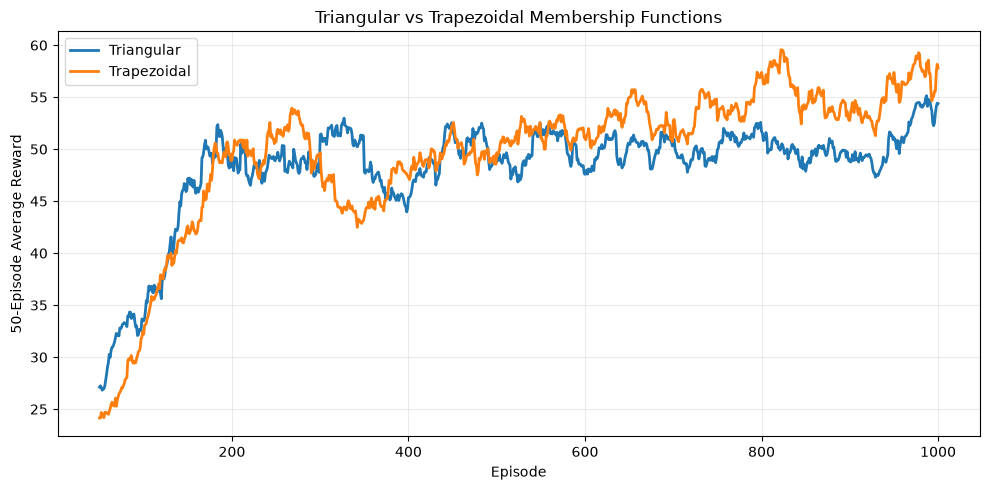

In [14]:
# Line chart: appropriate for showing learning behaviour across episodes.

plt.figure(figsize=(10, 5))

for result in membership_results:
    rewards = result["rewards"]
    plt.plot(
        np.arange(50, len(rewards) + 1),
        moving_average(rewards, 50),
        linewidth=2,
        label=result["label"]
    )

plt.xlabel("Episode")
plt.ylabel("50-Episode Average Reward")
plt.title("Triangular vs Trapezoidal Membership Functions")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

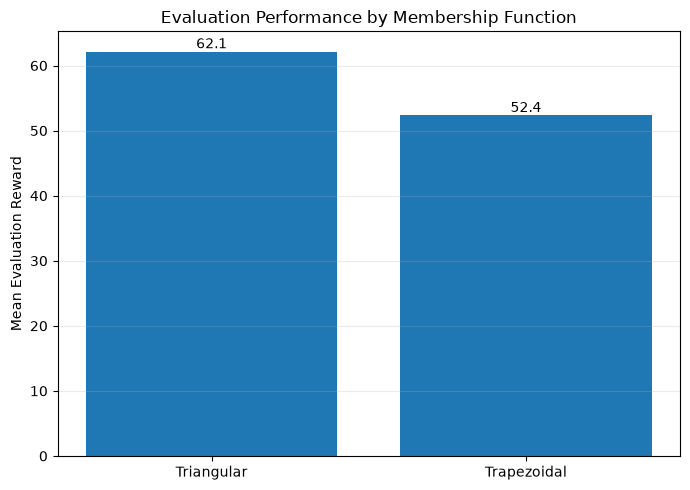

In [15]:
# Bar chart

plt.figure(figsize=(7, 5))
values = membership_summary["Evaluation Mean"]
bars = plt.bar(membership_summary["Experiment"], values)

plt.ylabel("Mean Evaluation Reward")
plt.title("Evaluation Performance by Membership Function")
plt.grid(axis="y", alpha=0.25)

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.1f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

### 6. Compare for Learning Rate = 0.01, 0.1 and 0.05

In [16]:
# Controlled comparison:
# 5 fuzzy sets, triangular membership, gamma = 0.9, 1000 episodes.

alpha_results = []

for alpha in [0.01, 0.05, 0.10]:
    config = AgentConfig(
        n_sets=5,
        membership="triangular",
        alpha=alpha,
        gamma=0.9
    )

    agent, rewards, lengths = train_agent(
        config,
        episodes=EPISODES,
        seed=SEED,
        verbose=False
    )

    evaluation = evaluate_agent(
        agent,
        episodes=20,
        seed=SEED + 10000
    )

    alpha_results.append({
        "label": f"Alpha = {alpha}",
        "config": config,
        "agent": agent,
        "rewards": rewards,
        "lengths": lengths,
        "evaluation": evaluation
    })

alpha_summary = make_summary(alpha_results)
alpha_summary

,Experiment,Fuzzy Sets,Membership,Alpha,Gamma,Final 50 Avg,Maximum Reward,Evaluation Mean,Evaluation Std
0,Alpha = 0.01,5,triangular,0.01,0.9,9.48,63.0,9.35,0.65
1,Alpha = 0.05,5,triangular,0.05,0.9,54.38,223.0,62.15,25.86
2,Alpha = 0.1,5,triangular,0.10,0.9,191.20,500.0,377.30,167.52


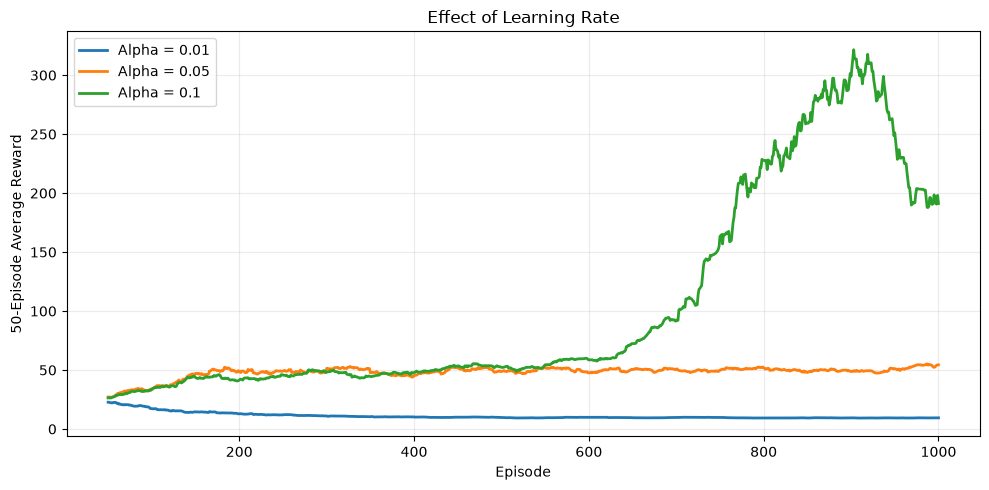

In [17]:
# Line chart: learning/convergence behaviour for the three learning rates.

plt.figure(figsize=(10, 5))

for result in alpha_results:
    rewards = result["rewards"]
    plt.plot(
        np.arange(50, len(rewards) + 1),
        moving_average(rewards, 50),
        linewidth=2,
        label=result["label"]
    )

plt.xlabel("Episode")
plt.ylabel("50-Episode Average Reward")
plt.title("Effect of Learning Rate")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

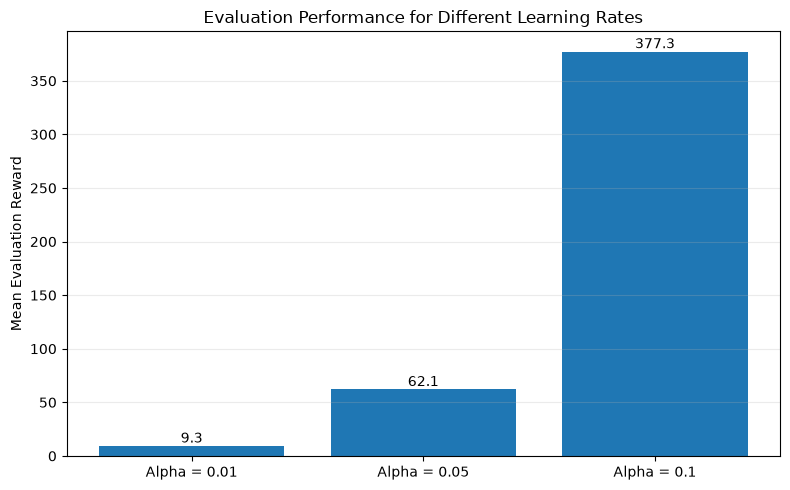

In [18]:
# Bar chart: final evaluation comparison.

plt.figure(figsize=(8, 5))
values = alpha_summary["Evaluation Mean"]
bars = plt.bar(alpha_summary["Experiment"], values)

plt.ylabel("Mean Evaluation Reward")
plt.title("Evaluation Performance for Different Learning Rates")
plt.grid(axis="y", alpha=0.25)

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.1f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

### 7. Compare for discount factor = 0.5 and 0.9

In [19]:
# Controlled comparison:
# 5 fuzzy sets, triangular membership, alpha = 0.05, 1000 episodes.

gamma_results = []

for gamma in [0.5, 0.9]:
    config = AgentConfig(
        n_sets=5,
        membership="triangular",
        alpha=0.05,
        gamma=gamma
    )

    agent, rewards, lengths = train_agent(
        config,
        episodes=EPISODES,
        seed=SEED,
        verbose=False
    )

    evaluation = evaluate_agent(
        agent,
        episodes=20,
        seed=SEED + 10000
    )

    gamma_results.append({
        "label": f"Gamma = {gamma}",
        "config": config,
        "agent": agent,
        "rewards": rewards,
        "lengths": lengths,
        "evaluation": evaluation
    })

gamma_summary = make_summary(gamma_results)
gamma_summary

,Experiment,Fuzzy Sets,Membership,Alpha,Gamma,Final 50 Avg,Maximum Reward,Evaluation Mean,Evaluation Std
0,Gamma = 0.5,5,triangular,0.05,0.5,55.84,282.0,57.35,25.07
1,Gamma = 0.9,5,triangular,0.05,0.9,54.38,223.0,62.15,25.86


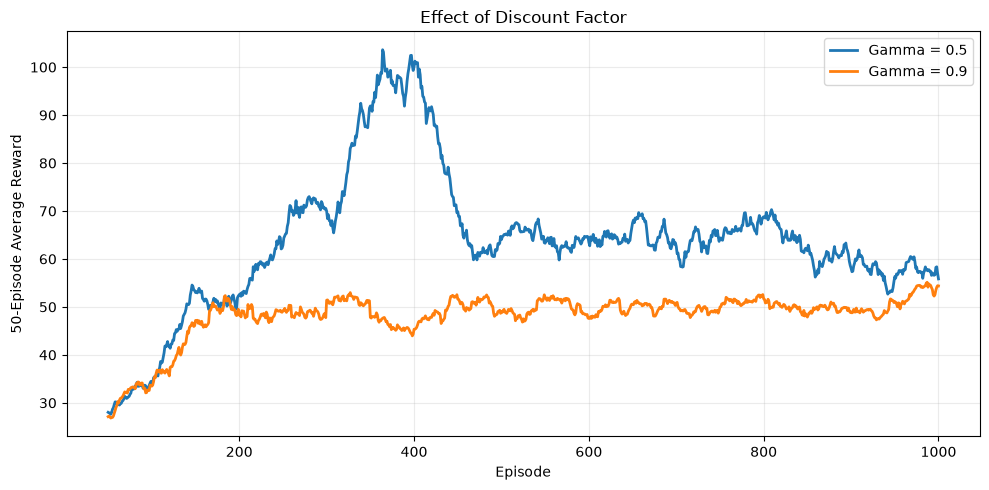

In [20]:
# Line chart: learning/convergence behaviour for the two discount factors.

plt.figure(figsize=(10, 5))

for result in gamma_results:
    rewards = result["rewards"]
    plt.plot(
        np.arange(50, len(rewards) + 1),
        moving_average(rewards, 50),
        linewidth=2,
        label=result["label"]
    )

plt.xlabel("Episode")
plt.ylabel("50-Episode Average Reward")
plt.title("Effect of Discount Factor")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

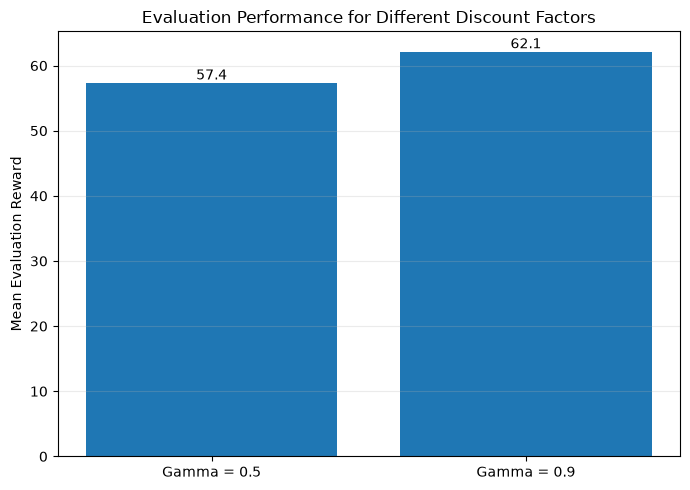

In [21]:
# Bar chart: final evaluation comparison.

plt.figure(figsize=(7, 5))
values = gamma_summary["Evaluation Mean"]
bars = plt.bar(gamma_summary["Experiment"], values)

plt.ylabel("Mean Evaluation Reward")
plt.title("Evaluation Performance for Different Discount Factors")
plt.grid(axis="y", alpha=0.25)

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.1f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [22]:
# Comparison of 2 and 5 fuzzy sets.

set_results = []

for n_sets in [2, 5]:
    config = AgentConfig(
        n_sets=n_sets,
        membership="triangular",
        alpha=0.05,
        gamma=0.9
    )

    agent, rewards, lengths = train_agent(
        config,
        episodes=EPISODES,
        seed=SEED,
        verbose=False
    )

    evaluation = evaluate_agent(
        agent,
        episodes=20,
        seed=SEED + 10000
    )

    set_results.append({
        "label": f"{n_sets} Fuzzy Sets",
        "config": config,
        "agent": agent,
        "rewards": rewards,
        "lengths": lengths,
        "evaluation": evaluation
    })

set_summary = make_summary(set_results)
set_summary

,Experiment,Fuzzy Sets,Membership,Alpha,Gamma,Final 50 Avg,Maximum Reward,Evaluation Mean,Evaluation Std
0,2 Fuzzy Sets,2,triangular,0.05,0.9,9.48,64.0,9.35,0.65
1,5 Fuzzy Sets,5,triangular,0.05,0.9,54.38,223.0,62.15,25.86


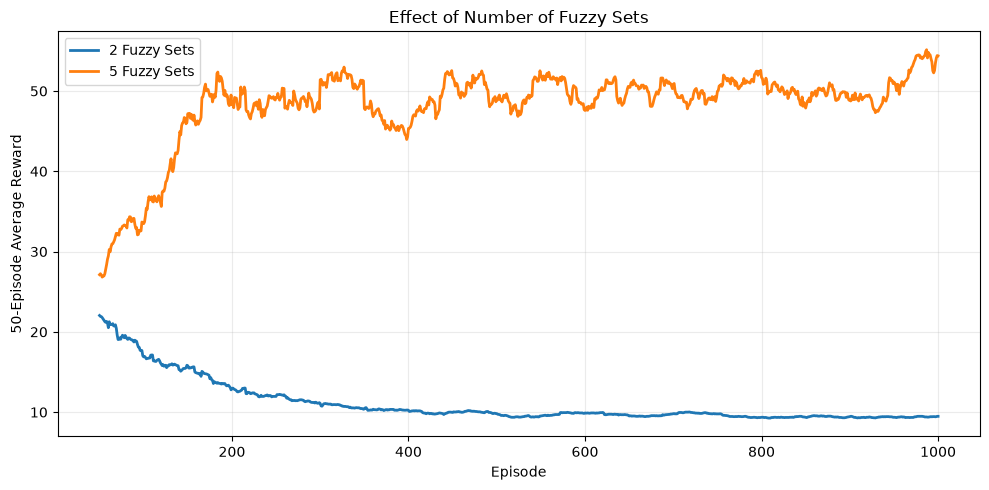

In [23]:
# Line chart for the required 2-set vs 5-set learning comparison.

plt.figure(figsize=(10, 5))

for result in set_results:
    rewards = result["rewards"]
    plt.plot(
        np.arange(50, len(rewards) + 1),
        moving_average(rewards, 50),
        linewidth=2,
        label=result["label"]
    )

plt.xlabel("Episode")
plt.ylabel("50-Episode Average Reward")
plt.title("Effect of Number of Fuzzy Sets")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

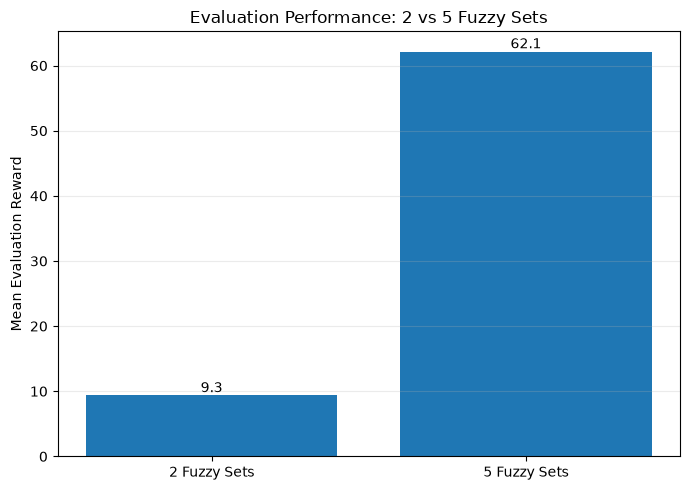

In [24]:
# Bar chart for final evaluation performance of 2 vs 5 fuzzy sets.

plt.figure(figsize=(7, 5))
values = set_summary["Evaluation Mean"]
bars = plt.bar(set_summary["Experiment"], values)

plt.ylabel("Mean Evaluation Reward")
plt.title("Evaluation Performance: 2 vs 5 Fuzzy Sets")
plt.grid(axis="y", alpha=0.25)

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.1f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [25]:
# Final comparison table containing all required experiments.

all_results = (
    set_results
    + membership_results
    + alpha_results
    + gamma_results
)

overall_summary = make_summary(all_results)
overall_summary

,Experiment,Fuzzy Sets,Membership,Alpha,Gamma,Final 50 Avg,Maximum Reward,Evaluation Mean,Evaluation Std
0,2 Fuzzy Sets,2,triangular,0.05,0.9,9.48,64.0,9.35,0.65
1,5 Fuzzy Sets,5,triangular,0.05,0.9,54.38,223.0,62.15,25.86
2,Triangular,5,triangular,0.05,0.9,54.38,223.0,62.15,25.86
3,Trapezoidal,5,trapezoidal,0.05,0.9,57.80,143.0,52.35,15.98
4,Alpha = 0.01,5,triangular,0.01,0.9,9.48,63.0,9.35,0.65
5,Alpha = 0.05,5,triangular,0.05,0.9,54.38,223.0,62.15,25.86
6,Alpha = 0.1,5,triangular,0.10,0.9,191.20,500.0,377.30,167.52
7,Gamma = 0.5,5,triangular,0.05,0.5,55.84,282.0,57.35,25.07
8,Gamma = 0.9,5,triangular,0.05,0.9,54.38,223.0,62.15,25.86
